# Function Transformation

- Handling skewed data (Non-Normal Distribution) 
- Reducing outliers (Function transformations compress large values, reducing the impact of outliers)
- When Feature Scaling is Required (Function transformations help bring all values to a similar range)

In [1]:
from sklearn.preprocessing import FunctionTransformer

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('loan_data_set.csv')
df.head(3)

# In this dataset the ApplicantIncome and CoapplicantIncome are non normal distributions

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y


In [4]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

## Without Outliers

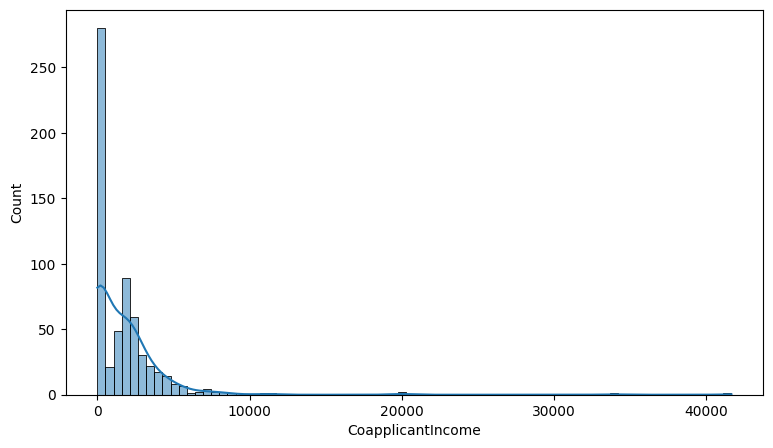

In [5]:
plt.figure(figsize=(9,5))
sns.histplot(df['CoapplicantIncome'], kde=True)
plt.show()

In [6]:
# Removing Outliers using IQR method
q1 = df['CoapplicantIncome'].quantile(0.25)
q3 = df['CoapplicantIncome'].quantile(0.75)

IQR = q3 - q1

q1, q3, IQR

(0.0, 2297.25, 2297.25)

In [7]:
min_range = q1 - (1.5 * IQR)
max_range = q3 + (1.5 * IQR)

min_range, max_range

(-3445.875, 5743.125)

In [8]:
new_df = df[df['CoapplicantIncome'] <= max_range]
new_df.head(3)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y


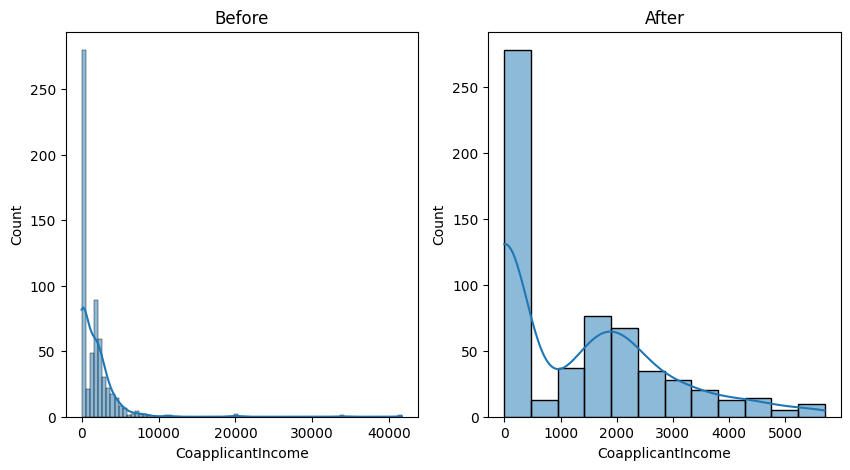

In [9]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.title("Before")
sns.histplot(df['CoapplicantIncome'], kde=True)

plt.subplot(1,2,2)
plt.title("After")
sns.histplot(new_df['CoapplicantIncome'], kde=True)
plt.show()

In [10]:
# Now caonverting into a Normal Distribution
ft = FunctionTransformer(func=np.log1p)

# np.log1p(x) = ln(1+x) 
# np.log1p(x) (Stable log for small x) → Used when x is close to 0, avoids precision errors in data transformations.

In [11]:
ft.fit(df[['CoapplicantIncome']])

FunctionTransformer(func=<ufunc 'log1p'>)

In [12]:
ft.transform(new_df[['CoapplicantIncome']])

,CoapplicantIncome
0,0.000000
1,7.319202
2,0.000000
3,7.765993
4,0.000000
...,...
609,0.000000
610,0.000000
611,5.484797
612,0.000000


In [13]:
new_df['CoapplicantIncome_ft'] = ft.transform(df[['CoapplicantIncome']])
new_df.head(3)

C:\Users\atkar\AppData\Local\Temp\ipykernel_1568\902884968.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df['CoapplicantIncome_ft'] = ft.transform(df[['CoapplicantIncome']])


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,CoapplicantIncome_ft
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y,0.000000
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,7.319202
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,0.000000


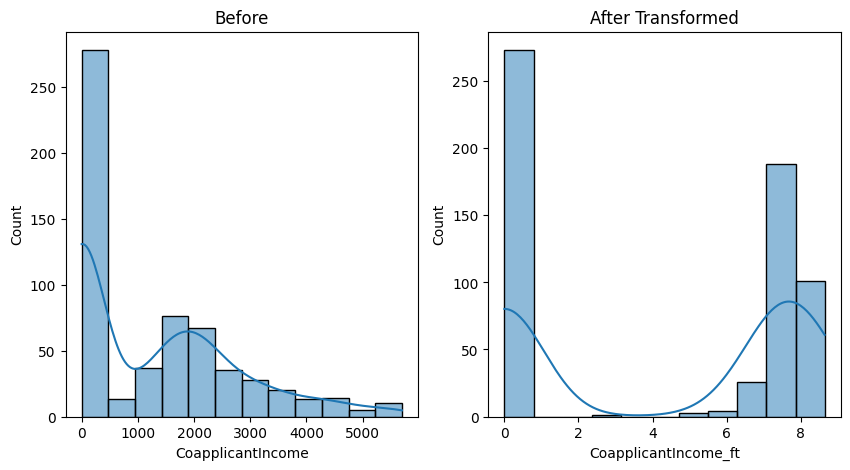

In [14]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.title("Before")
sns.histplot(new_df['CoapplicantIncome'], kde=True)

plt.subplot(1,2,2)
plt.title("After Transformed")
sns.histplot(new_df['CoapplicantIncome_ft'], kde=True)

plt.show()

We can see that the After Transformed graph is verly like correct/near, also there are no outliers now (the tail is completely removed)

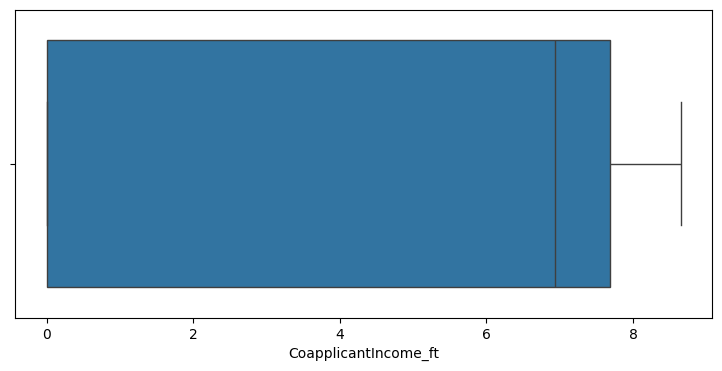

In [15]:
plt.figure(figsize=(9,4))
sns.boxplot(x='CoapplicantIncome_ft', data=new_df)
plt.show()

---

## With Outliers

In [16]:
df.head(3)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y


In [17]:
df.shape

(614, 13)

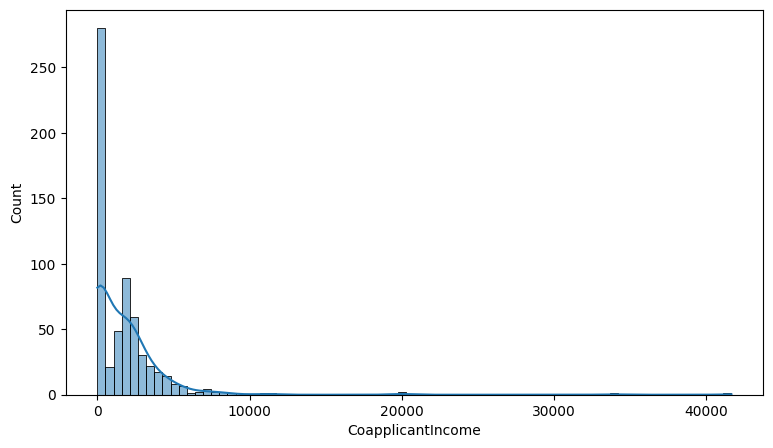

In [18]:
plt.figure(figsize=(9,5))
sns.histplot(df['CoapplicantIncome'], kde=True)
plt.show()

In [19]:
ft = FunctionTransformer(func=np.log1p)

In [20]:
ft.fit(df[['CoapplicantIncome']])

FunctionTransformer(func=<ufunc 'log1p'>)

In [21]:
df['CoapplicantIncome_ft'] = ft.transform(df[['CoapplicantIncome']])
df.head(3)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,CoapplicantIncome_ft
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y,0.000000
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,7.319202
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,0.000000


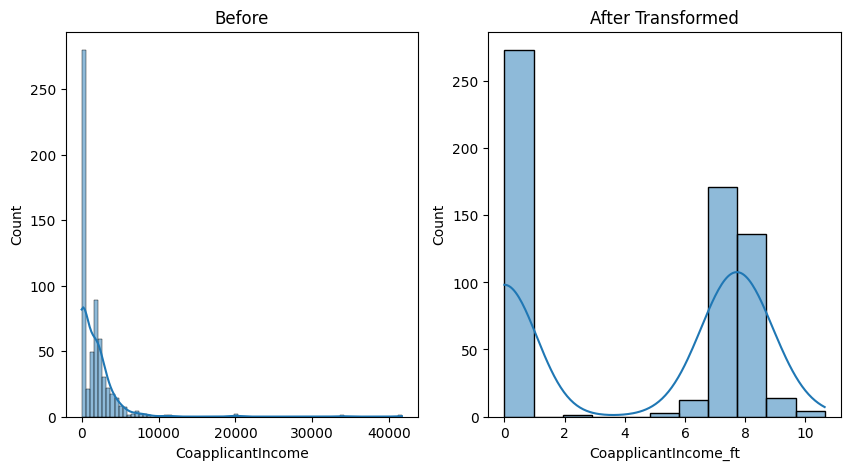

In [22]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.title("Before")
sns.histplot(df['CoapplicantIncome'], kde=True)

plt.subplot(1,2,2)
plt.title("After Transformed")
sns.histplot(df['CoapplicantIncome_ft'], kde=True)

plt.show()

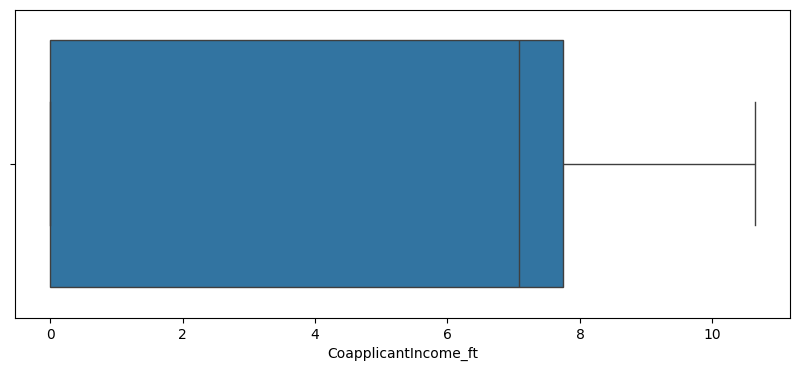

In [23]:
plt.figure(figsize=(10,4))
sns.boxplot(x='CoapplicantIncome_ft', data=df)
plt.show()

---